# ANA-072 — Structure relevant to learning and navigation

This notebook describes the **already fitted RUN-186 landscapes**. It does not
train a predictor, launch an optimizer, fit parameters, resample a landscape,
or run adaptive walks. It reconstructs the saved deterministic maps and reduces
their static graph structure. The strict-uphill reachability and neutral-component
values are read from the original RUN's exact graph calculations.

Learnability and searchability are different questions. Neighbor correlation
indicates local smoothness that a learner might exploit, but does not establish
prediction accuracy or sample complexity. Local traps and reachability describe
constraints on one-substitution ascent, but do not establish performance of an
algorithm with nonlocal proposals, model-based jumps, finite query budgets or noise.
No universal easy/hard score or classification is assigned.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'labproject.yaml').exists())
ANA = PROJECT / 'analyses/2026-11-25_ANA-072_run-186-trpb-landscape-behaviour-architecture-and-difficulty-proxies'
sys.path.insert(0, str(ANA / 'notebooks'))
from average_tools import Context
from difficulty_tools import (validate_edge_moments, graph_table, all_edge_moments,
    summarize, zero_threshold_invariance, figure_static, figure_resolution)
ctx = Context(PROJECT)
TABLES = ANA / 'tables'
TABLES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## What is compared, and what is held fixed?

Every full map uses the **same 159,129 measured genotypes** and **6,016,433
undirected single-amino-acid-substitution edges**, restricted from the four-site
q20 Hamming graph. Missing genotypes are removed from empirical and synthetic
comparisons alike. A restricted graph can contain traps or disconnect paths that
would disappear with unmeasured variants; these conclusions concern this mask.

Three independently calibrated observation assumptions retain their selected
r values: no error (r=4), independent replicate error (r=2), and shared-stop
sensitivity (r=0.5). Their readouts differ too, so the rows are not a controlled
sweep of r. Intrinsic values are the noiseless oracle; observed values add the
original frozen replicate-error construction and average two replicates. The
shared-stop layer is an observation **sensitivity assumption**, not a demonstrated
error mechanism. Observed-map errors are fixed by genotype in this analysis;
repeated noisy oracle queries are not being studied.

The eight original **fresh** generator seeds are primary; all 16 reused seeds
remain visible or tabulated separately. Fresh refers to the RUN-180 seed design:
these seeds were already inspected in earlier analyses and are not independent
biological validation. Seed ranges are generator variability, not confidence
intervals or biological-replicate uncertainty.

In [2]:
small_graph_checks = validate_edge_moments()
graph = graph_table(ctx)
edge = all_edge_moments(ctx)
invariance_checks = zero_threshold_invariance(ctx, graph)
graph.to_csv(TABLES / 'difficulty_graph_seed_metrics.csv', index=False)
edge.to_csv(TABLES / 'difficulty_edge_seed_metrics.csv', index=False)
keys = ['cohort', 'observation', 'layer', 'relative_resolution']
graph_metrics = ['no_beneficial_fraction', 'inaccessible_top_fraction', 'accessible_top',
                 'neutral_edge_fraction', 'all_largest_fraction',
                 'above_floor_largest_fraction', 'above_floor_component_fraction_all_nodes']
graph_summary = summarize(graph, graph_metrics, keys)
edge_summary = summarize(edge, ['neighbor_correlation', 'normalized_edge_rms'], keys[:-1])
graph_summary.to_csv(TABLES / 'difficulty_graph_summary.csv', index=False)
edge_summary.to_csv(TABLES / 'difficulty_edge_summary.csv', index=False)
verification = dict(
    small_graph_bruteforce_checks=small_graph_checks,
    maps_summarized=len(edge),
    common_nodes=int(edge.nodes.iloc[0]), common_edges=int(edge.edges.iloc[0]),
    map_reconstruction_checks=ctx.reconstruction_checks,
    maximum_saved_cube_replay_error=max(x['maximum_absolute_difference'] for x in ctx.reconstruction_checks),
    zero_threshold_monotone_invariance_checks=invariance_checks,
    graph_summary_source='RUN-186/outputs/graph_summary.csv',
    new_learning_or_optimization_tasks=0,
    interpretation='Static descriptive proxies only; no task-specific difficulty classification.')
(TABLES / 'difficulty_verification.json').write_text(json.dumps(verification, indent=2) + '\n')
print(f'Checked {len(small_graph_checks)} independent small graph cases; summarized {len(edge)} fixed maps.')
print(f'All {len(invariance_checks)} latent-to-intrinsic zero-threshold topology comparisons agree.')

Checked 6 independent small graph cases; summarized 121 fixed maps.
All 216 latent-to-intrinsic zero-threshold topology comparisons agree.


## Figure 5 — Local predictability and uphill accessibility need separate descriptors

**Neighbor correlation** is Pearson correlation between the fitnesses at the two
ends of a uniformly selected undirected edge, including both orientations. Each
genotype is weighted by its measured-graph degree. We compute its moments exactly
from q20 single-site fibers, without enumerating paths or fitting a predictor.
If v_e is the endpoint-weighted variance, then
r_neighbor = 1 − E_edge[(f(v) − f(u))²] / (2 v_e).
The tables also retain RMS edge difference divided by the uniform-node fitness SD.
High local correlation is useful structural information; it does not say whether
a given learner can predict rare high-fitness variants or global interactions.

**Nodes without a beneficial neighbor** have no allowed mutation with gain > ε.
At ε>0 these include resolution-limited traps, rather than only strict local
maxima. **No uphill path to the top 1%** means no sequence of allowed single
substitutions with every gain > ε reaches that map's own ≥99th percentile.
Starting inside the target counts as already accessible. Paths have no query
budget; reachability is not an algorithm's probability of finding the path.
The target is a relative rank threshold in each map, not equal absolute fitness.
Here ε=0.001 × the original empirical calibration range ≈0.000194 native units.
These topology metrics were not targets of the calibration loss.

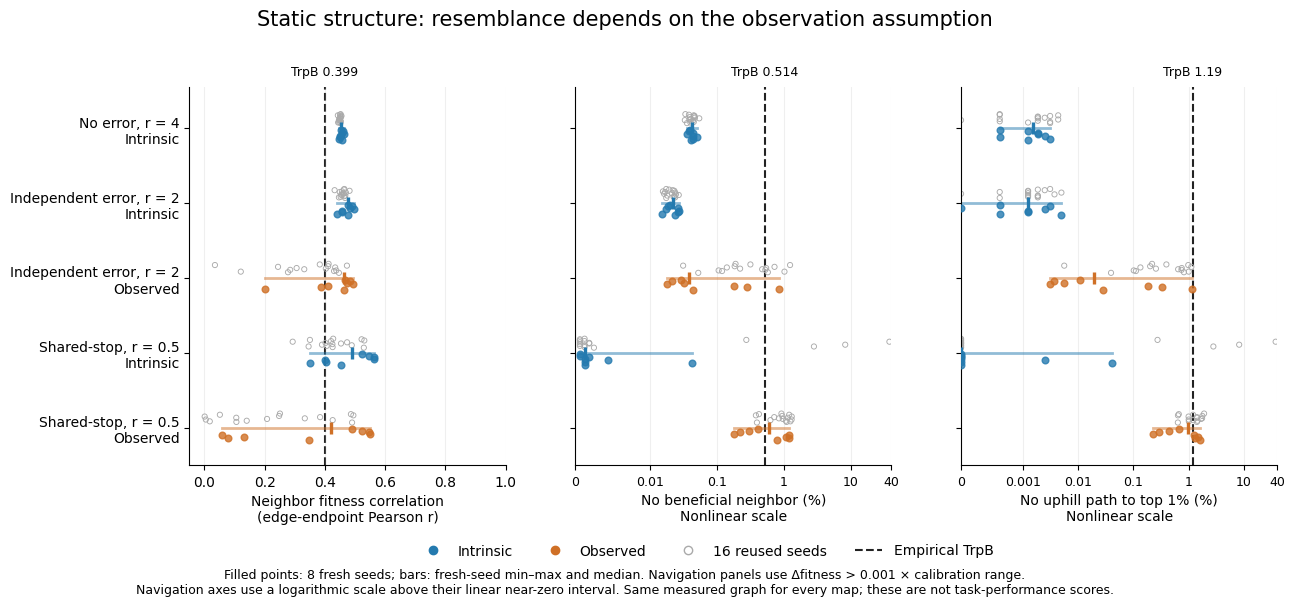

,cohort,observation,layer,median,minimum,maximum
0,empirical,measured,empirical,0.398971,0.398971,0.398971
12,fresh,none,intrinsic,0.454914,0.447504,0.462242
14,fresh,independent_difference,intrinsic,0.476282,0.439517,0.497245
16,fresh,independent_difference,observed,0.464514,0.200875,0.493843
18,fresh,shared_stop_sensitivity,intrinsic,0.488572,0.349262,0.564593
20,fresh,shared_stop_sensitivity,observed,0.419003,0.058984,0.550776


,cohort,observation,layer,metric,median,minimum,maximum
7,empirical,measured,empirical,no_beneficial_fraction,0.005140,0.005140,0.005140
8,empirical,measured,empirical,inaccessible_top_fraction,0.011896,0.011896,0.011896
133,fresh,none,intrinsic,no_beneficial_fraction,0.000424,0.000364,0.000509
134,fresh,none,intrinsic,inaccessible_top_fraction,0.000016,0.000006,0.000031
154,fresh,independent_difference,intrinsic,no_beneficial_fraction,0.000220,0.000151,0.000270
155,fresh,independent_difference,intrinsic,inaccessible_top_fraction,0.000013,0.000000,0.000050
175,fresh,independent_difference,observed,no_beneficial_fraction,0.000380,0.000182,0.008421
176,fresh,independent_difference,observed,inaccessible_top_fraction,0.000195,0.000031,0.011733
196,fresh,shared_stop_sensitivity,intrinsic,no_beneficial_fraction,0.000013,0.000006,0.000421
197,fresh,shared_stop_sensitivity,intrinsic,inaccessible_top_fraction,0.000000,0.000000,0.000408


In [3]:
fig5 = figure_static(ctx, graph, edge)
display(fig5)
plt.close(fig5)
primary_edge = edge_summary[(edge_summary.cohort.isin(['fresh', 'empirical'])) &
                            (edge_summary.metric == 'neighbor_correlation')]
primary_graph = graph_summary[(graph_summary.cohort.isin(['fresh', 'empirical'])) &
    (graph_summary.relative_resolution == .001) &
    (graph_summary.metric.isin(['no_beneficial_fraction', 'inaccessible_top_fraction']))]
display(primary_edge[['cohort', 'observation', 'layer', 'median', 'minimum', 'maximum']])
display(primary_graph[['cohort', 'observation', 'layer', 'metric', 'median', 'minimum', 'maximum']])

## Figure 6 — Resolution and the observation layer change apparent neutrality

A neutral edge has |Δfitness|≤ε. Its connected components are defined by chains
of such edges; the endpoints of a long chain can differ by much more than ε.
Thus "large neutral component" must not be read as "nearly constant function."
The lower panels restrict the component calculation to fitness above the fixed
calibration floor and normalize by the number of above-floor genotypes. The
middle panels instead include all measured genotypes. This prevents a near-floor
connected region from automatically being interpreted as a useful high-fitness
neutral network. The all-node version of the restricted component fraction is
also retained in the tables.

The three resolutions (0, 0.001 and 0.01 times the calibration range) were already
part of RUN-186. No threshold is chosen to improve agreement after seeing these
results. A positive monotone sigmoid preserves latent ordering at exact resolution;
all archived latent/intrinsic zero-threshold trap and reachability comparisons
are explicitly checked above. Finite resolution and observation noise can still
change apparent structure substantially.

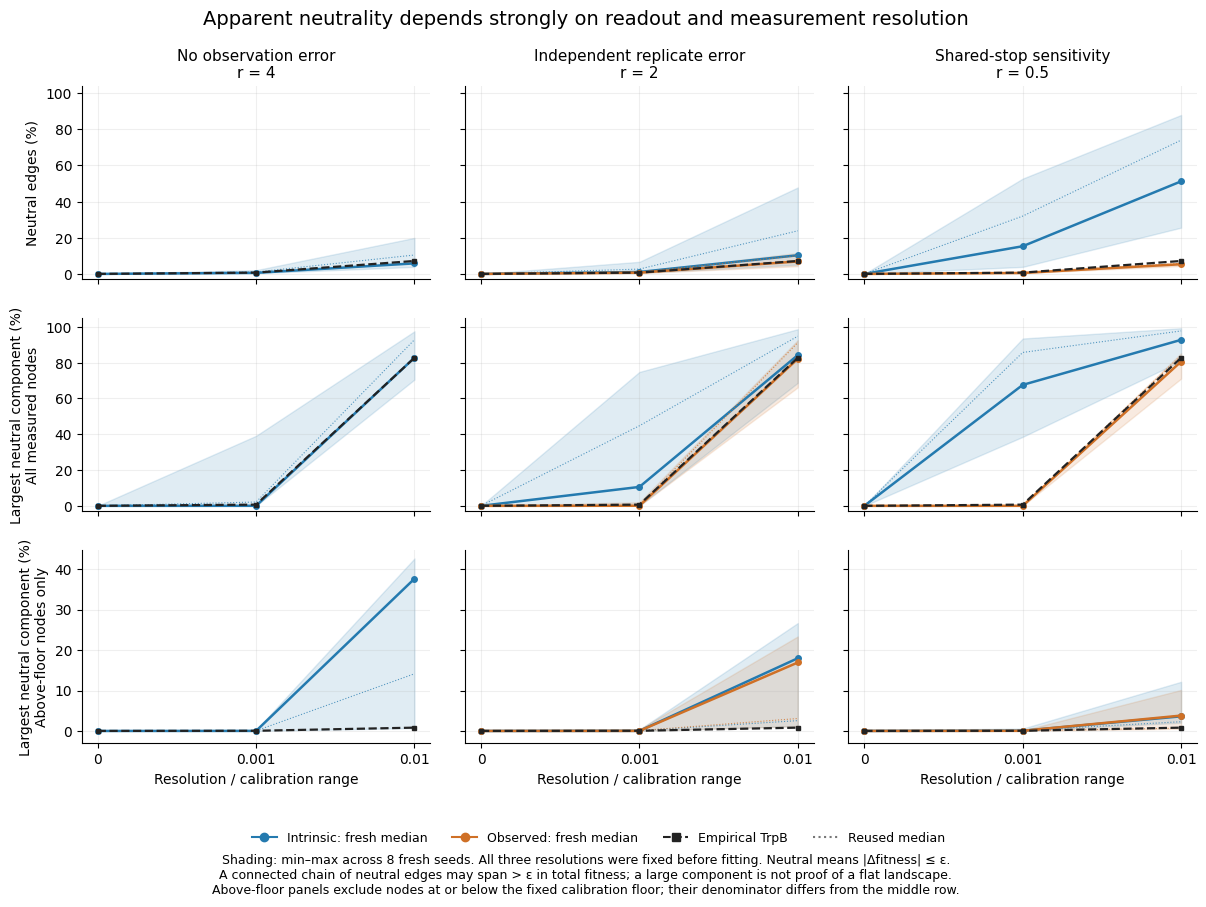

,cohort,observation,layer,metric,median,minimum,maximum
10,empirical,measured,empirical,neutral_edge_fraction,0.007209,0.007209,0.007209
11,empirical,measured,empirical,all_largest_fraction,0.006793,0.006793,0.006793
136,fresh,none,intrinsic,neutral_edge_fraction,0.005891,0.003867,0.020650
137,fresh,none,intrinsic,all_largest_fraction,0.000223,0.000088,0.391205
157,fresh,independent_difference,intrinsic,neutral_edge_fraction,0.010600,0.005137,0.066881
158,fresh,independent_difference,intrinsic,all_largest_fraction,0.105700,0.000610,0.747859
178,fresh,independent_difference,observed,neutral_edge_fraction,0.006909,0.004308,0.011666
179,fresh,independent_difference,observed,all_largest_fraction,0.000487,0.000151,0.020047
199,fresh,shared_stop_sensitivity,intrinsic,neutral_edge_fraction,0.153191,0.038828,0.527355
200,fresh,shared_stop_sensitivity,intrinsic,all_largest_fraction,0.675571,0.385480,0.934682


In [4]:
fig6 = figure_resolution(ctx, graph)
display(fig6)
plt.close(fig6)
display(graph_summary[(graph_summary.cohort.isin(['fresh', 'empirical'])) &
    (graph_summary.relative_resolution == .001) &
    (graph_summary.metric.isin(['neutral_edge_fraction', 'all_largest_fraction']))]
    [['cohort', 'observation', 'layer', 'metric', 'median', 'minimum', 'maximum']])

## What the evidence permits

Compare these graph descriptors with the independent observable spectral and
epistasis figures in `architecture.ipynb`. They constrain plausible benchmark
behavior, but neither coefficients nor graph shape uniquely determine a learner's
or optimizer's difficulty. No learning curve, recovery accuracy, acquisition
policy, task budget, top-variant discovery rate, or four-quadrant classification
is measured here. HYP-011 and HYP-012 remain prospective.

The no-error and independent-error fitted landscapes have substantially fewer
resolution-limited traps and almost universal uphill access to their own top 1%,
compared with measured TrpB. The shared-stop observed model comes much closer on
those navigation descriptors; its intrinsic oracle is much smoother topologically.
Consequently, resemblance that requires the observation sensitivity must not be
attributed automatically to the noiseless online environment. Neutral component
size has additional threshold dependence and is not reproduced uniformly across
resolutions. These are conditional, metric-specific approximations, rather than
evidence that all aspects of task challengingness match TrpB.